Matplotlib Session 9 – Advanced Charts in Matplotlib

TIFFIN SERVICE - DAILY ORDER REPORT
---------------------------------------------
      date  veg  jain  diet  total_orders
2025-01-01  222    29    24           275
2025-01-02  212    24    31           267
2025-01-03  134    55    24           213
2025-01-04  226    53    31           310
2025-01-05  191    50    34           275
2025-01-06  140    29    38           207
2025-01-07  222    38    19           279
2025-01-08  241    51    48           340
2025-01-09  194    20    20           234
2025-01-10  207    24    16           247

Dataset Shape: (365, 5)
Total Annual Orders: 100027
Average Daily Orders: 274.05


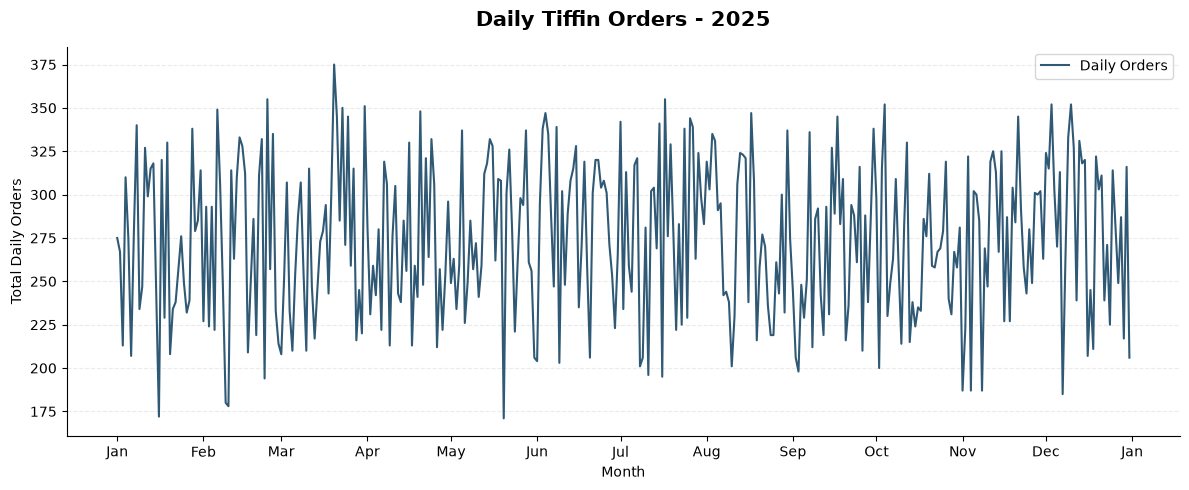


CSV saved: tiffin_daily.csv
Session 9 - Task 1 completed successfully!


In [1]:

# MATPLOTLIB SESSION 9 - TASK 1
# Daily Tiffin Service Order Analysis - 2025

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

# Reproducible synthetic business data
np.random.seed(42)

# Generate daily dates for the full year 2025
dates = pd.date_range(
    start="2025-01-01",
    periods=365,
    freq="D"
)

# Create daily order records
df = pd.DataFrame({
    "date": dates,
    "veg": np.random.randint(120, 261, size=365),
    "jain": np.random.randint(20, 71, size=365),
    "diet": np.random.randint(15, 61, size=365)
})

# Calculate total orders for each day
df["total_orders"] = (
    df["veg"] +
    df["jain"] +
    df["diet"]
)

# Validate dataset
assert len(df) == 365
assert df["date"].is_unique
assert (df[["veg", "jain", "diet"]] >= 0).all().all()

# Save dataset
output_file = Path("tiffin_daily.csv")
df.to_csv(output_file, index=False)

# Display first 10 records
print("TIFFIN SERVICE - DAILY ORDER REPORT")
print("-" * 45)
print(df.head(10).to_string(index=False))

print("\nDataset Shape:", df.shape)
print("Total Annual Orders:", df["total_orders"].sum())
print("Average Daily Orders:", round(df["total_orders"].mean(), 2))

# Create time-series chart
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    df["date"],
    df["total_orders"],
    color="#0B3C5D",
    linewidth=1.5,
    alpha=0.85,
    label="Daily Orders"
)

# Format X-axis with month names
ax.xaxis.set_major_locator(
    mdates.MonthLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b")
)

# Chart formatting
ax.set_title(
    "Daily Tiffin Orders - 2025",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Month")
ax.set_ylabel("Total Daily Orders")

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.legend(loc="upper right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
plt.show()

print("\nCSV saved:", output_file)
print("Session 9 - Task 1 completed successfully!")


Task 2: Monthly Stacked Bar Chart

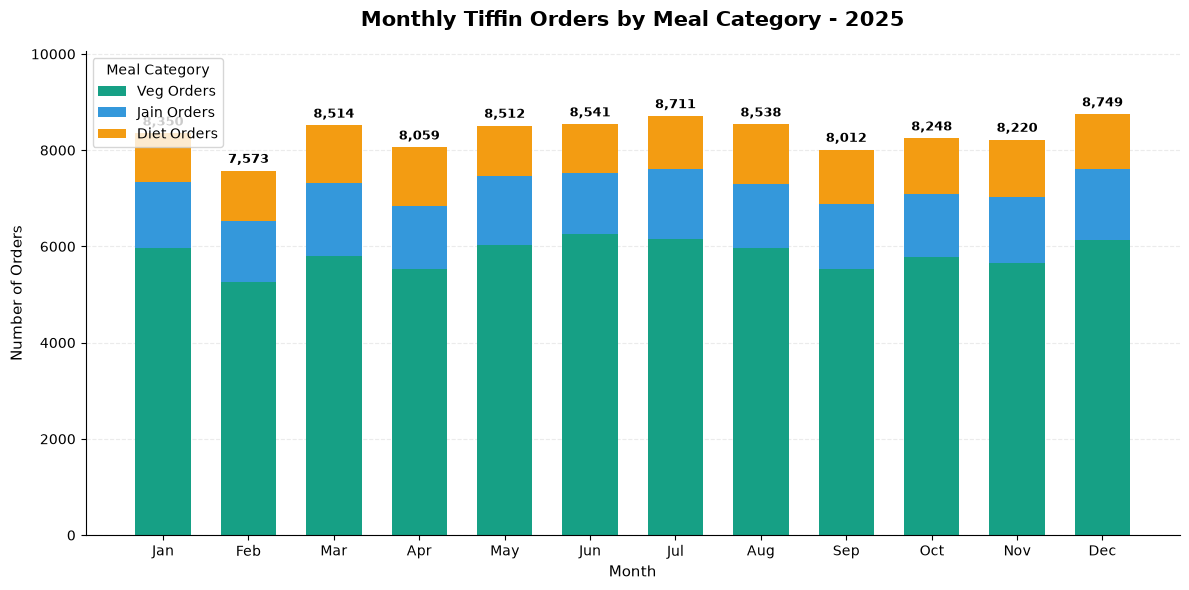

MONTHLY TIFFIN ORDER SUMMARY - 2025
--------------------------------------------------
             veg  jain  diet  total_orders
date                                      
2025-01-01  5973  1365  1012          8350
2025-02-01  5258  1273  1042          7573
2025-03-01  5811  1505  1198          8514
2025-04-01  5522  1327  1210          8059
2025-05-01  6023  1449  1040          8512
2025-06-01  6254  1279  1008          8541
2025-07-01  6162  1446  1103          8711
2025-08-01  5961  1346  1231          8538
2025-09-01  5529  1362  1121          8012
2025-10-01  5777  1303  1168          8248
2025-11-01  5656  1362  1202          8220
2025-12-01  6142  1459  1148          8749

Annual Orders by Category:
veg     70068
jain    16476
diet    13483

Total Annual Orders: 100027

Chart saved: tiffin_stacked_bar.png
Session 9 - Task 2 completed successfully!


In [2]:

# MATPLOTLIB SESSION 9 - TASK 2
# Monthly Tiffin Orders - Stacked Bar Chart

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load daily tiffin orders
df = pd.read_csv(
    "tiffin_daily.csv",
    parse_dates=["date"]
)

# Validate required columns
required_columns = {"date", "veg", "jain", "diet"}
missing = required_columns - set(df.columns)

if missing:
    raise ValueError(f"Missing columns: {missing}")

# Convert daily data into monthly totals
monthly_orders = (
    df.set_index("date")[["veg", "jain", "diet"]]
    .resample("MS")
    .sum()
)

# Calculate total monthly orders
monthly_orders["total_orders"] = (
    monthly_orders["veg"]
    + monthly_orders["jain"]
    + monthly_orders["diet"]
)

# Prepare chart values
months = monthly_orders.index.strftime("%b")

veg_orders = monthly_orders["veg"].to_numpy()
jain_orders = monthly_orders["jain"].to_numpy()
diet_orders = monthly_orders["diet"].to_numpy()

# Create professional chart
fig, ax = plt.subplots(figsize=(12, 6))

# First stack - Veg orders
ax.bar(
    months,
    veg_orders,
    label="Veg Orders",
    color="#16A085",
    width=0.65
)

# Second stack - Jain orders
ax.bar(
    months,
    jain_orders,
    bottom=veg_orders,
    label="Jain Orders",
    color="#3498DB",
    width=0.65
)

# Third stack - Diet orders
ax.bar(
    months,
    diet_orders,
    bottom=veg_orders + jain_orders,
    label="Diet Orders",
    color="#F39C12",
    width=0.65
)

# Add monthly total labels
for i, total in enumerate(monthly_orders["total_orders"]):
    ax.text(
        i,
        total + 100,
        f"{total:,}",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

# Professional formatting
ax.set_title(
    "Monthly Tiffin Orders by Meal Category - 2025",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Number of Orders", fontsize=11)

ax.set_ylim(
    0,
    monthly_orders["total_orders"].max() * 1.15
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)
ax.legend(title="Meal Category")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()

# Save chart BEFORE displaying
fig.savefig(
    "tiffin_stacked_bar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Print monthly business summary
print("MONTHLY TIFFIN ORDER SUMMARY - 2025")
print("-" * 50)
print(monthly_orders.to_string())

print("\nAnnual Orders by Category:")
print(
    monthly_orders[["veg", "jain", "diet"]]
    .sum()
    .to_string()
)

print("\nTotal Annual Orders:",
      monthly_orders["total_orders"].sum())

print("\nChart saved: tiffin_stacked_bar.png")
print("Session 9 - Task 2 completed successfully!")


Task 3: Professional Stacked Area Chart

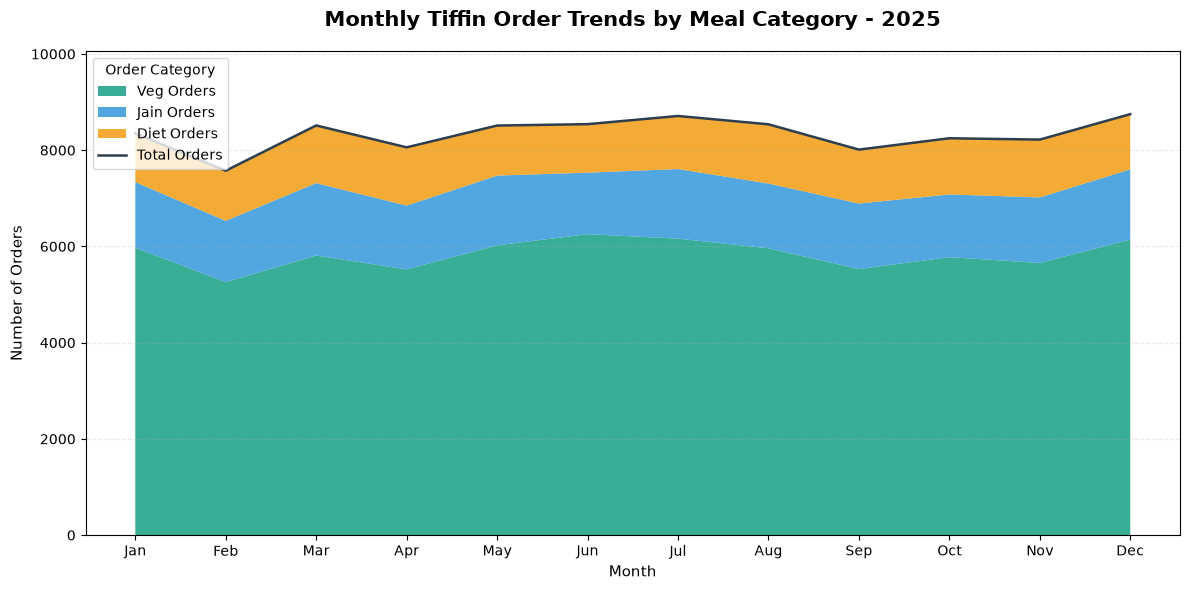

MONTHLY TIFFIN ORDER ANALYSIS
---------------------------------------------
             veg  jain  diet  total_orders
date                                      
2025-01-01  5973  1365  1012          8350
2025-02-01  5258  1273  1042          7573
2025-03-01  5811  1505  1198          8514
2025-04-01  5522  1327  1210          8059
2025-05-01  6023  1449  1040          8512
2025-06-01  6254  1279  1008          8541
2025-07-01  6162  1446  1103          8711
2025-08-01  5961  1346  1231          8538
2025-09-01  5529  1362  1121          8012
2025-10-01  5777  1303  1168          8248
2025-11-01  5656  1362  1202          8220
2025-12-01  6142  1459  1148          8749

Highest Order Month: December
Highest Monthly Orders: 8749

Total Annual Orders: 100027

Chart saved: tiffin_area.png
Session 9 - Task 3 completed successfully!


In [3]:

# MATPLOTLIB SESSION 9 - TASK 3
# Monthly Tiffin Orders - Stacked Area Chart

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load daily order dataset
df = pd.read_csv(
    "tiffin_daily.csv",
    parse_dates=["date"]
)

# Validate dataset
required_columns = {"date", "veg", "jain", "diet"}
missing_columns = required_columns - set(df.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )

# Convert daily orders into monthly totals
monthly_orders = (
    df.set_index("date")[["veg", "jain", "diet"]]
    .resample("MS")
    .sum()
)

# Prepare X-axis and category data
months = np.arange(1, len(monthly_orders) + 1)

month_labels = monthly_orders.index.strftime("%b")

veg_orders = monthly_orders["veg"].to_numpy()
jain_orders = monthly_orders["jain"].to_numpy()
diet_orders = monthly_orders["diet"].to_numpy()

# Calculate monthly totals
total_orders = veg_orders + jain_orders + diet_orders

# Create professional area chart
plt.figure(figsize=(12, 6))

# Stack the three meal categories
plt.stackplot(
    months,
    veg_orders,
    jain_orders,
    diet_orders,
    labels=["Veg Orders", "Jain Orders", "Diet Orders"],
    colors=["#16A085", "#3498DB", "#F39C12"],
    alpha=0.85
)

# Draw a line along the top of the stacked area
plt.plot(
    months,
    total_orders,
    color="#2C3E50",
    linewidth=1.8,
    label="Total Orders"
)

# Add chart title and axis labels
plt.title(
    "Monthly Tiffin Order Trends by Meal Category - 2025",
    fontsize=15,
    fontweight="bold",
    pad=18
)

plt.xlabel("Month", fontsize=11)
plt.ylabel("Number of Orders", fontsize=11)

# Display month names
plt.xticks(months, month_labels)

# Start Y-axis from zero
plt.ylim(0, total_orders.max() * 1.15)

# Add light horizontal grid lines
plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

# Display category legend
plt.legend(
    loc="upper left",
    title="Order Category"
)

plt.tight_layout()

# Save BEFORE displaying
plt.savefig(
    "tiffin_area.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Business summary
print("MONTHLY TIFFIN ORDER ANALYSIS")
print("-" * 45)

summary = monthly_orders.copy()
summary["total_orders"] = total_orders

print(summary.to_string())

print("\nHighest Order Month:",
      summary["total_orders"].idxmax().strftime("%B"))

print("Highest Monthly Orders:",
      summary["total_orders"].max())

print("\nTotal Annual Orders:",
      summary["total_orders"].sum())

print("\nChart saved: tiffin_area.png")
print("Session 9 - Task 3 completed successfully!")


Task 4: Monthly Error Bar Chart

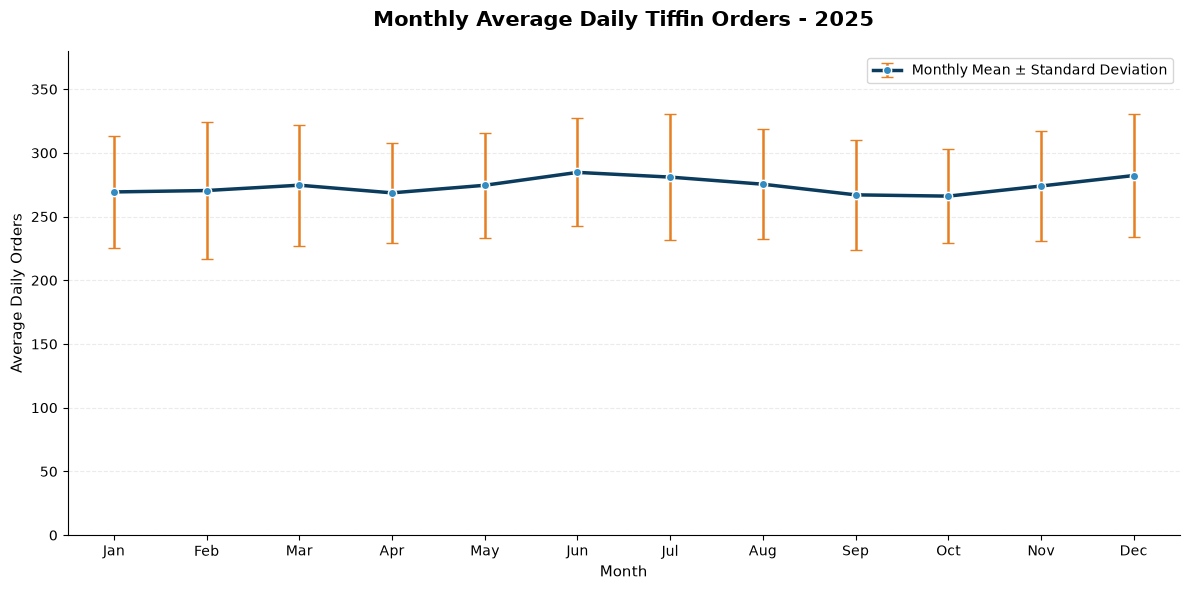

MONTHLY TIFFIN ORDER STATISTICS - 2025
--------------------------------------------------
         mean    std
Month               
Jan    269.35  44.06
Feb    270.46  54.12
Mar    274.65  47.45
Apr    268.63  39.04
May    274.58  41.02
Jun    284.70  42.36
Jul    281.00  49.41
Aug    275.42  43.04
Sep    267.07  43.18
Oct    266.06  36.89
Nov    274.00  43.11
Dec    282.23  47.96

Overall Average Daily Orders: 274.05
Overall Daily Order Std Dev: 44.18

Saved: tiffin_errorbar.png
File Size: 135.4 KB
Session 9 - Task 4 completed successfully!


In [4]:

# MATPLOTLIB SESSION 9 - TASK 4
# Monthly Average Daily Orders with Standard Deviation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load daily tiffin orders
df = pd.read_csv(
    "tiffin_daily.csv",
    parse_dates=["date"]
)

# Validate required columns
required = {"date", "veg", "jain", "diet"}
missing = required - set(df.columns)

if missing:
    raise ValueError(f"Missing columns: {sorted(missing)}")

# Ensure dates and order values are valid
if df["date"].isna().any():
    raise ValueError("Dataset contains invalid dates.")

order_columns = ["veg", "jain", "diet"]

for column in order_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="raise"
    )

if df[order_columns].isna().any().any():
    raise ValueError("Dataset contains missing order values.")

if (df[order_columns] < 0).any().any():
    raise ValueError("Order counts cannot be negative.")

# Calculate total orders per day
df["total_orders"] = df[order_columns].sum(axis=1)

# Calculate monthly mean and standard deviation
monthly_stats = (
    df.groupby(df["date"].dt.month)["total_orders"]
    .agg(["mean", "std"])
    .reindex(range(1, 13))
)

# Validate monthly statistics
if monthly_stats.isna().any().any():
    raise ValueError(
        "Monthly statistics are incomplete. "
        "Check that each month contains enough daily records."
    )

# Prepare chart data
months = np.arange(1, 13)

month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

monthly_mean = monthly_stats["mean"].to_numpy()
monthly_std = monthly_stats["std"].to_numpy()

# Create professional error bar chart
fig, ax = plt.subplots(figsize=(12, 6))

ax.errorbar(
    months,
    monthly_mean,
    yerr=monthly_std,
    fmt="o-",
    capsize=4,
    color="#0B3C5D",
    ecolor="#E67E22",
    linewidth=2.5,
    elinewidth=1.8,
    markersize=6,
    markerfacecolor="#328CC1",
    markeredgecolor="white",
    label="Monthly Mean ± Standard Deviation"
)

# Chart formatting
ax.set_title(
    "Monthly Average Daily Tiffin Orders - 2025",
    fontsize=15,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Month", fontsize=11)
ax.set_ylabel("Average Daily Orders", fontsize=11)

ax.set_xticks(months)
ax.set_xticklabels(month_names)

ax.set_xlim(0.5, 12.5)
ax.set_ylim(
    0,
    max(monthly_mean + monthly_std) * 1.15
)

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.25
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(loc="upper right")

fig.tight_layout()

# Save BEFORE displaying
fig.savefig(
    "tiffin_errorbar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Print monthly statistics
monthly_report = monthly_stats.copy()
monthly_report.index = month_names
monthly_report.index.name = "Month"

print("MONTHLY TIFFIN ORDER STATISTICS - 2025")
print("-" * 50)
print(monthly_report.round(2).to_string())

print("\nOverall Average Daily Orders:",
      round(df["total_orders"].mean(), 2))

print("Overall Daily Order Std Dev:",
      round(df["total_orders"].std(), 2))

output = Path("tiffin_errorbar.png")

print(f"\nSaved: {output.name}")
print(f"File Size: {output.stat().st_size / 1024:.1f} KB")
print("Session 9 - Task 4 completed successfully!")
